In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, hamming_loss, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             multilabel_confusion_matrix, make_scorer)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

df = pd.read_csv("data_amazon.xlsx - Sheet1.csv")
LABEL_COLS = ["Materials", "Construction", "Color", "Finishing", "Durability"]

print("Ukuran data:", df.shape)
display(df.head())

Ukuran data: (49338, 9)


,Title,Review,Cons_rating,Cloth_class,Materials,Construction,Color,Finishing,Durability
0,NaN,Absolutely wonderful - silky and sexy and comfortable,4.0,Intimates,0.0,0.0,0.0,1.0,0.0
1,NaN,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have orde...",5.0,Dresses,0.0,1.0,0.0,0.0,0.0
2,Some major design flaws,I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my u...,3.0,Dresses,0.0,0.0,0.0,1.0,0.0
3,My favorite buy!,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get nothing but great comp...",5.0,Pants,0.0,0.0,0.0,0.0,0.0
4,Flattering shirt,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length to wear with leggings...,5.0,Blouses,0.0,1.0,0.0,0.0,0.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 49338 entries, 0 to 49337
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Title         45370 non-null  str    
 1   Review        48507 non-null  str    
 2   Cons_rating   49124 non-null  float64
 3   Cloth_class   49322 non-null  str    
 4   Materials     5741 non-null   float64
 5   Construction  5743 non-null   float64
 6   Color         5742 non-null   float64
 7   Finishing     5737 non-null   float64
 8   Durability    5734 non-null   float64
dtypes: float64(6), str(3)
memory usage: 3.4 MB


In [5]:
miss = df.isna().sum().to_frame("missing")
miss["persen"] = (miss["missing"] / len(df) * 100).round(2)
display(miss)

# Berapa baris yang benar-benar punya label?
n_terisi = df[LABEL_COLS].notna().sum(axis=1)
print("Baris tanpa label sama sekali :", (n_terisi == 0).sum())
print("Baris dengan 1-4 label terisi :", ((n_terisi > 0) & (n_terisi < 5)).sum())
print("Baris dengan 5 label terisi   :", (n_terisi == 5).sum())

# Nilai pada tiap kolom label (seharusnya hanya 0 dan 1)
for c in LABEL_COLS:
    print(c, df[c].value_counts(dropna=False).to_dict())

print("\nDuplikat baris:", df.duplicated().sum())
print("Jumlah kelas pakaian:", df["Cloth_class"].nunique())

,missing,persen
Title,3968,8.04
Review,831,1.68
Cons_rating,214,0.43
Cloth_class,16,0.03
Materials,43597,88.36
Construction,43595,88.36
Color,43596,88.36
Finishing,43601,88.37
Durability,43604,88.38


Baris tanpa label sama sekali : 43594
Baris dengan 1-4 label terisi : 19
Baris dengan 5 label terisi   : 5725
Materials {nan: 43597, 0.0: 3989, 1.0: 1751, 9.0: 1}
Construction {nan: 43595, 1.0: 2893, 0.0: 2849, 2.0: 1}
Color {nan: 43596, 0.0: 4258, 1.0: 1483, 9.0: 1}
Finishing {nan: 43601, 0.0: 4212, 1.0: 1525}
Durability {nan: 43604, 0.0: 4514, 1.0: 1219, 9.0: 1}

Duplikat baris: 1118
Jumlah kelas pakaian: 24


In [6]:
# 1. Ambil hanya baris yang kelima labelnya terisi
lab = df[df[LABEL_COLS].notna().all(axis=1)].copy()
print("Baris dengan 5 label terisi:", lab.shape[0])

# 2. Buang baris dengan nilai label di luar 0/1 (salah input)
lab = lab[lab[LABEL_COLS].isin([0, 1]).all(axis=1)]
print("Setelah membuang nilai bukan 0/1:", lab.shape[0])

# 3. Gabungkan judul dan isi review menjadi satu teks
lab["text"] = (lab["Title"].fillna("") + " " + lab["Review"].fillna("")).str.strip()
lab = lab[lab["text"].str.len() > 2]
print("Setelah membuang teks kosong:", lab.shape[0])

# 4. Buang duplikat (teks dan label sama) agar tidak bocor antara train dan test
lab = lab.drop_duplicates(subset=["text"] + LABEL_COLS).reset_index(drop=True)
print("Setelah membuang duplikat:", lab.shape[0])

X = lab["text"]
Y = lab[LABEL_COLS].astype(int)

# Subset berlabel tidak mewakili seluruh data, cek perbedaannya
print("\nRata-rata rating: berlabel =", round(lab["Cons_rating"].mean(), 2),
      "| seluruh data =", round(df["Cons_rating"].mean(), 2))
print("Proporsi Dresses : berlabel =", round((lab["Cloth_class"] == "Dresses").mean(), 3),
      "| seluruh data =", round((df["Cloth_class"] == "Dresses").mean(), 3))

Baris dengan 5 label terisi: 5725
Setelah membuang nilai bukan 0/1: 5723
Setelah membuang teks kosong: 5723
Setelah membuang duplikat: 5703

Rata-rata rating: berlabel = 3.88 | seluruh data = 4.1
Proporsi Dresses : berlabel = 0.445 | seluruh data = 0.174


In [7]:
jumlah_label = Y.sum(axis=1)
kardinalitas = jumlah_label.mean()
densitas = kardinalitas / Y.shape[1]

print(f"Label cardinality : {kardinalitas:.3f} (rata-rata label per review)")
print(f"Label density     : {densitas:.3f}")
print(f"Review tanpa label aktif: {(jumlah_label == 0).sum()} ({(jumlah_label == 0).mean()*100:.1f}%)")
print(f"Review dengan >1 label  : {(jumlah_label > 1).sum()} ({(jumlah_label > 1).mean()*100:.1f}%)")
print(f"Kombinasi label unik    : {Y.astype(str).agg(''.join, axis=1).nunique()}")

per_label = pd.DataFrame({"jumlah_positif": Y.sum(),
                          "persen": (Y.mean() * 100).round(2)}).sort_values("jumlah_positif", ascending=False)
display(per_label)

Label cardinality : 1.548 (rata-rata label per review)
Label density     : 0.310
Review tanpa label aktif: 484 (8.5%)
Review dengan >1 label  : 2796 (49.0%)
Kombinasi label unik    : 32


,jumlah_positif,persen
Construction,2883,50.55
Materials,1744,30.58
Finishing,1521,26.67
Color,1478,25.92
Durability,1201,21.06


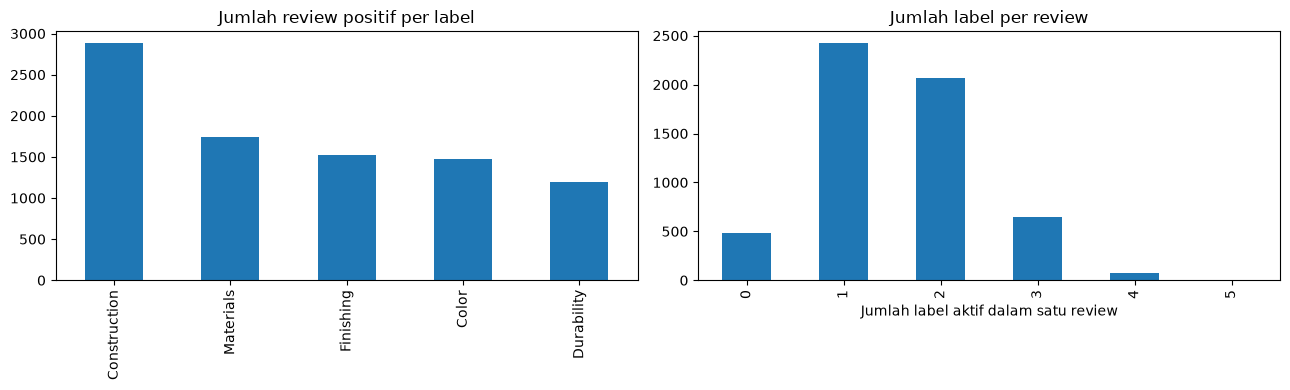

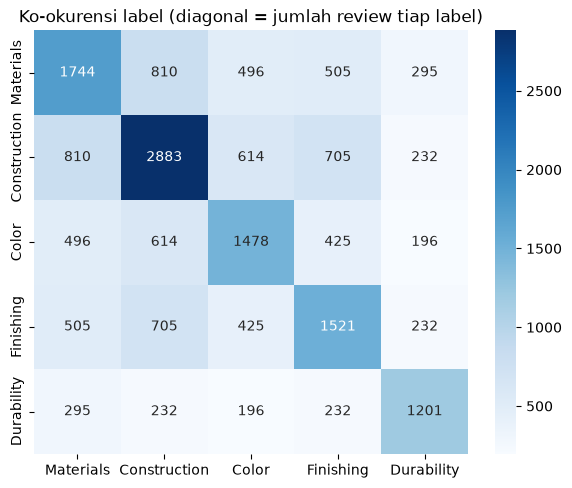

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
per_label["jumlah_positif"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Jumlah review positif per label")
jumlah_label.value_counts().sort_index().plot(kind="bar", ax=axes[1])
axes[1].set_title("Jumlah label per review")
axes[1].set_xlabel("Jumlah label aktif dalam satu review")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5.5))
sns.heatmap(Y.T.dot(Y), annot=True, fmt="d", cmap="Blues")
plt.title("Ko-okurensi label (diagonal = jumlah review tiap label)")
plt.show()

In [9]:
# Panjang review dan contoh review per label
lab["jumlah_kata"] = lab["text"].str.split().str.len()
print("Panjang review (kata):")
display(lab["jumlah_kata"].describe().round(1).to_frame("jumlah_kata").T)

for label in LABEL_COLS:
    print(f"\n--- Contoh review berlabel {label} ---")
    for t in lab.loc[Y[label] == 1, "text"].head(2):
        print("*", t[:200])

Panjang review (kata):


,count,mean,std,min,25%,50%,75%,max
jumlah_kata,5703.0,42.4,32.9,2.0,17.0,34.0,59.0,365.0



--- Contoh review berlabel Materials ---
* Perfect!!! More and more i find myself reliant on the reviews written by savvy shoppers before me and for the most past, they are right on in their estimation of the product. in the case of this dress
* Nice, but not for my body I took these out of the package and wanted them to fit so badly, but i could tell before i put them on that they wouldn't. these are for an hour-glass figure. i am more strai

--- Contoh review berlabel Construction ---
* Love this dress!  it's sooo pretty.  i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's petite.  i bought a petite and am 5'8".  i love the length on 
* Flattering shirt This shirt is very flattering to all due to the adjustable front tie. it is the perfect length to wear with leggings and it is sleeveless so it pairs well with any cardigan. love this

--- Contoh review berlabel Color ---
* Not for the very petite I love tracy reese dresses, but this 

In [10]:
# stratify tidak bisa dipakai langsung pada target multilabel
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42)

print("Train:", X_train.shape[0], "| Test:", X_test.shape[0])

cek = pd.DataFrame({"positif_train": Y_train.sum(), "positif_test": Y_test.sum()})
cek["persen_train"] = (Y_train.mean() * 100).round(1)
cek["persen_test"] = (Y_test.mean() * 100).round(1)
display(cek)

Train: 4562 | Test: 1141


,positif_train,positif_test,persen_train,persen_test
Materials,1386,358,30.4,31.4
Construction,2299,584,50.4,51.2
Color,1164,314,25.5,27.5
Finishing,1200,321,26.3,28.1
Durability,983,218,21.5,19.1


In [11]:
def buat_pipeline(clf):
    return Pipeline([
        ("tfidf", TfidfVectorizer(stop_words="english", ngram_range=(1, 2),
                                  min_df=2, sublinear_tf=True)),
        ("clf", OneVsRestClassifier(clf)),
    ])

models = {
    "Logistic Regression (balanced)": buat_pipeline(LogisticRegression(max_iter=3000, class_weight="balanced")),
    "Linear SVM (balanced)": buat_pipeline(LinearSVC(class_weight="balanced")),
    "Logistic Regression": buat_pipeline(LogisticRegression(max_iter=3000)),
    "Naive Bayes": buat_pipeline(MultinomialNB()),
}

# KFold biasa (StratifiedKFold tidak mendukung target multilabel)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "subset_accuracy": "accuracy",
    "f1_micro": "f1_micro",
    "f1_macro": "f1_macro",
    "f1_samples": "f1_samples",
    "hamming_loss": make_scorer(hamming_loss),
}

rows = []
for nama, model in models.items():
    hasil = cross_validate(model, X_train, Y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": nama, **{m: hasil[f"test_{m}"].mean() for m in scoring}})

hasil_cv = pd.DataFrame(rows).set_index("Model").round(4).sort_values("f1_macro", ascending=False)
display(hasil_cv)

nol = np.zeros_like(Y_train.values)
print("Pembanding tebak semua 0 -> hamming loss:", round(hamming_loss(Y_train, nol), 4),
      "| subset accuracy:", round(accuracy_score(Y_train, nol), 4))

,subset_accuracy,f1_micro,f1_macro,f1_samples,hamming_loss
Model,,,,,
Logistic Regression (balanced),0.5377,0.8044,0.8037,0.7424,0.1218
Linear SVM (balanced),0.5292,0.7965,0.7958,0.7314,0.1256
Logistic Regression,0.4757,0.7271,0.7001,0.6589,0.1456
Naive Bayes,0.3391,0.5392,0.4025,0.4868,0.2115


Pembanding tebak semua 0 -> hamming loss: 0.3083 | subset accuracy: 0.0857


In [12]:
def skor_label(model, X_):
    """Skor per label: probabilitas jika tersedia, jika tidak pakai decision function."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_)
    return model.decision_function(X_)

fitted, rows = {}, []
for nama, model in models.items():
    model.fit(X_train, Y_train)
    pred = model.predict(X_test)
    skor = skor_label(model, X_test)
    fitted[nama] = model

    rows.append({
        "Model": nama,
        "Subset accuracy": accuracy_score(Y_test, pred),
        "Hamming loss": hamming_loss(Y_test, pred),
        "Precision (micro)": precision_score(Y_test, pred, average="micro", zero_division=0),
        "Recall (micro)": recall_score(Y_test, pred, average="micro", zero_division=0),
        "F1 (micro)": f1_score(Y_test, pred, average="micro", zero_division=0),
        "F1 (macro)": f1_score(Y_test, pred, average="macro", zero_division=0),
        "F1 (samples)": f1_score(Y_test, pred, average="samples", zero_division=0),
        "ROC-AUC (macro)": roc_auc_score(Y_test, skor, average="macro"),
    })

hasil_test = pd.DataFrame(rows).set_index("Model").round(4).sort_values("F1 (macro)", ascending=False)
display(hasil_test)

,Subset accuracy,Hamming loss,Precision (micro),Recall (micro),F1 (micro),F1 (macro),F1 (samples),ROC-AUC (macro)
Model,,,,,,,,
Logistic Regression (balanced),0.5451,0.1185,0.8089,0.8162,0.8125,0.8119,0.7450,0.9291
Linear SVM (balanced),0.5215,0.1229,0.8136,0.7905,0.8019,0.8027,0.7260,0.9220
Logistic Regression,0.4575,0.1488,0.8589,0.6306,0.7273,0.7023,0.6514,0.9287
Naive Bayes,0.3164,0.2210,0.8041,0.3933,0.5282,0.4042,0.4779,0.8569


In [13]:
nama_terbaik = hasil_cv.index[0]          # dipilih berdasarkan cross-validation
terbaik = fitted[nama_terbaik]
pred = terbaik.predict(X_test)
skor = skor_label(terbaik, X_test)

print("Model terbaik (menurut CV):", nama_terbaik)
print(classification_report(Y_test, pred, target_names=LABEL_COLS, zero_division=0))

auc_label = pd.Series({c: roc_auc_score(Y_test[c], skor[:, i]) for i, c in enumerate(LABEL_COLS)})
display(auc_label.round(3).to_frame("ROC-AUC"))

Model terbaik (menurut CV): Logistic Regression (balanced)
              precision    recall  f1-score   support

   Materials       0.72      0.75      0.73       358
Construction       0.85      0.83      0.84       584
       Color       0.86      0.88      0.87       314
   Finishing       0.77      0.79      0.78       321
  Durability       0.84      0.84      0.84       218

   micro avg       0.81      0.82      0.81      1795
   macro avg       0.81      0.82      0.81      1795
weighted avg       0.81      0.82      0.81      1795
 samples avg       0.77      0.77      0.75      1795



,ROC-AUC
Materials,0.878
Construction,0.920
Color,0.966
Finishing,0.907
Durability,0.974


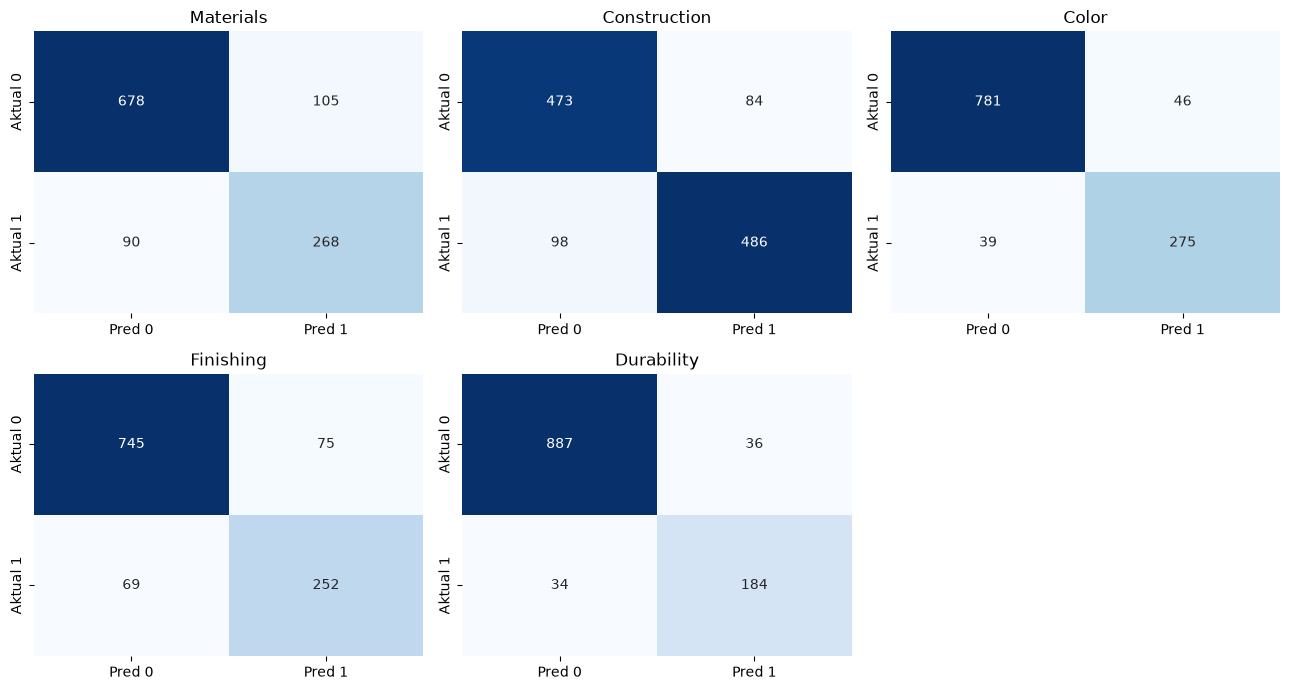

In [14]:
mcm = multilabel_confusion_matrix(Y_test, pred)
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, m, nama in zip(axes.ravel(), mcm, LABEL_COLS):
    sns.heatmap(m, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["Aktual 0", "Aktual 1"])
    ax.set_title(nama)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [15]:
# Kata dengan bobot terbesar untuk tiap label (khusus Logistic Regression)
lr = fitted["Logistic Regression (balanced)"]
kata = np.array(lr.named_steps["tfidf"].get_feature_names_out())
koef = lr.named_steps["clf"].estimators_

for i, label in enumerate(LABEL_COLS):
    top = kata[np.argsort(koef[i].coef_[0])[-8:][::-1]]
    print(f"{label:13s}:", ", ".join(top))

Materials    : fabric, material, stretch, stretchy, warm, sheer, lightweight, light
Construction : flattering, fit, size, fits, small, short, large, length
Color        : color, colors, blue, black, green, pink, red, white
Finishing    : comfortable, soft, comfy, cozy, itchy, scratchy, comfort, feel
Durability   : durable, pilling, ripped, wash, apart, tear, washed, zipper


In [16]:
review_baru = [
    "The fabric feels cheap and thin, and it started pilling after one wash.",
    "Beautiful color, exactly like the picture. The stitching is neat too.",
    "The zipper broke after two weeks and a seam came apart.",
]

pred_baru = terbaik.predict(pd.Series(review_baru))
hasil = pd.DataFrame({
    "review": review_baru,
    "label_prediksi": [", ".join(np.array(LABEL_COLS)[row == 1]) or "(tidak ada)" for row in pred_baru],
})
display(hasil)

import joblib
joblib.dump({"model": terbaik, "label": LABEL_COLS}, "model_multilabel_amazon.pkl")
print("Model tersimpan: model_multilabel_amazon.pkl")

,review,label_prediksi
0,"The fabric feels cheap and thin, and it started pilling after one wash.","Materials, Durability"
1,"Beautiful color, exactly like the picture. The stitching is neat too.",Color
2,The zipper broke after two weeks and a seam came apart.,Durability


Model tersimpan: model_multilabel_amazon.pkl
